In [1]:

import numpy as np
import scipy
import matplotlib.pyplot as plt

print("MiniFEM - 2D Finite Element Solver")
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Environment ready!")


MiniFEM - 2D Finite Element Solver
NumPy version: 2.1.3
SciPy version: 1.16.3
Environment ready!


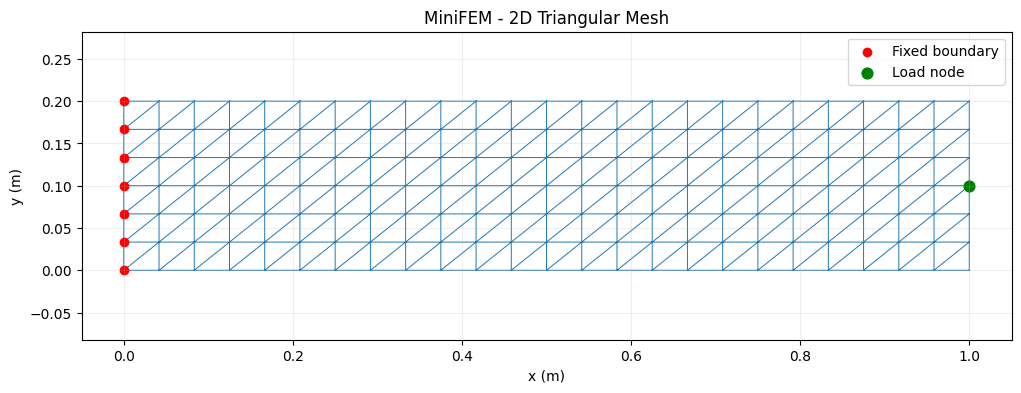

Number of nodes: 175
Number of elements: 288
Number of fixed nodes: 7


In [2]:

# Step 2: 2D triangular mesh generation
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

# Geometry (meters)
L = 1.0
H = 0.2

# Mesh resolution
nx = 24
ny = 6

# Generate nodes
nodes = np.array([
    [i * L / nx, j * H / ny]
    for j in range(ny + 1)
    for i in range(nx + 1)
])

# Generate triangular elements
elements = []

for j in range(ny):
    for i in range(nx):
        n0 = j * (nx + 1) + i
        n1 = n0 + 1
        n2 = n0 + nx + 1
        n3 = n2 + 1

        elements.append([n0, n1, n3])
        elements.append([n0, n3, n2])

elements = np.array(elements)

# Boundary nodes
fixed_nodes = np.where(
    np.isclose(nodes[:, 0], 0.0)
)[0]

# Load application node
load_node = (ny // 2) * (nx + 1) + nx

# Create mesh plot
triangulation = mtri.Triangulation(
    nodes[:, 0],
    nodes[:, 1],
    elements
)

plt.figure(figsize=(12, 4))

plt.triplot(triangulation, linewidth=0.7)

plt.scatter(
    nodes[fixed_nodes, 0],
    nodes[fixed_nodes, 1],
    color="red",
    label="Fixed boundary"
)

plt.scatter(
    nodes[load_node, 0],
    nodes[load_node, 1],
    color="green",
    s=60,
    label="Load node"
)

plt.title("MiniFEM - 2D Triangular Mesh")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Number of nodes:", len(nodes))
print("Number of elements:", len(elements))
print("Number of fixed nodes:", len(fixed_nodes))


=== MiniFEM Solver Results ===
Total DOFs: 350
Free DOFs: 336
Tip vertical displacement: -0.00021947716305597255 m
Maximum displacement magnitude: 0.00022145860245638597 m


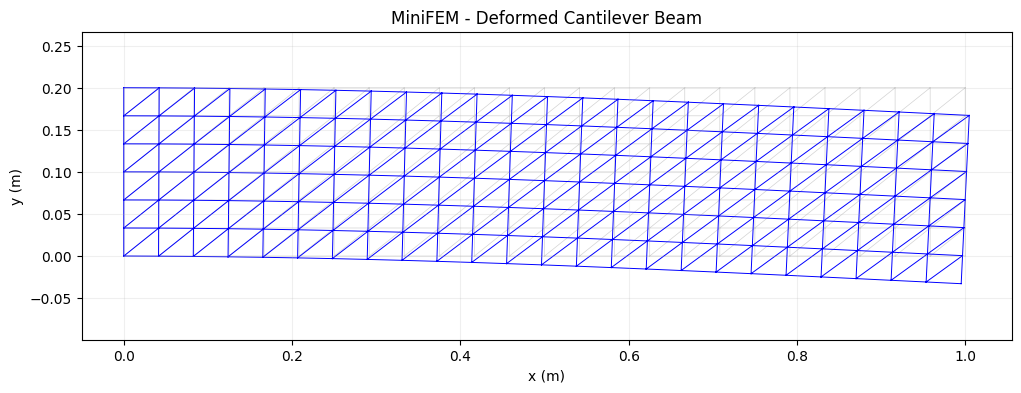

In [3]:

# Step 3: Finite Element Solver
# 2D Linear Elasticity - Plane Stress

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

# ----------------------------------------
# 1. Material properties
# ----------------------------------------

E = 210e9          # Young's modulus (Pa)
nu = 0.30          # Poisson's ratio
thickness = 0.01  # Thickness (m)
P = 1000.0         # Applied force (N)

# Plane stress constitutive matrix
D = E / (1 - nu**2) * np.array([
    [1, nu, 0],
    [nu, 1, 0],
    [0, 0, (1-nu)/2]
])

# ----------------------------------------
# 2. Assemble global stiffness matrix
# ----------------------------------------

ndof = 2 * len(nodes)

rows = []
cols = []
values = []

for element in elements:

    x = nodes[element, 0]
    y = nodes[element, 1]

    # Triangle area
    A = 0.5 * np.linalg.det(np.array([
        [1, x[0], y[0]],
        [1, x[1], y[1]],
        [1, x[2], y[2]]
    ]))

    if A <= 0:
        raise ValueError("Invalid triangle orientation")

    # Shape function derivatives
    b = np.array([
        y[1]-y[2],
        y[2]-y[0],
        y[0]-y[1]
    ])

    c = np.array([
        x[2]-x[1],
        x[0]-x[2],
        x[1]-x[0]
    ])

    # Strain-displacement matrix
    B = np.zeros((3, 6))

    B[0, 0::2] = b
    B[1, 1::2] = c
    B[2, 0::2] = c
    B[2, 1::2] = b

    B = B / (2 * A)

    # Element stiffness matrix
    Ke = thickness * A * (B.T @ D @ B)

    # Global degrees of freedom
    dofs = np.column_stack((
        2 * element,
        2 * element + 1
    )).ravel()

    # Sparse matrix assembly
    rows.extend(np.repeat(dofs, 6))
    cols.extend(np.tile(dofs, 6))
    values.extend(Ke.ravel())

K = coo_matrix(
    (values, (rows, cols)),
    shape=(ndof, ndof)
).tocsr()

# ----------------------------------------
# 3. Apply loads and boundary conditions
# ----------------------------------------

F = np.zeros(ndof)

# Downward point force
F[2 * load_node + 1] = -P

# Fixed boundary: ux = uy = 0
fixed_dofs = np.column_stack((
    2 * fixed_nodes,
    2 * fixed_nodes + 1
)).ravel()

free_dofs = np.setdiff1d(
    np.arange(ndof),
    fixed_dofs
)

# ----------------------------------------
# 4. Solve the linear system
# ----------------------------------------

U = np.zeros(ndof)

U[free_dofs] = spsolve(
    K[free_dofs][:, free_dofs],
    F[free_dofs]
)

ux = U[0::2]
uy = U[1::2]

print("=== MiniFEM Solver Results ===")
print("Total DOFs:", ndof)
print("Free DOFs:", len(free_dofs))
print("Tip vertical displacement:",
      uy[load_node], "m")
print("Maximum displacement magnitude:",
      np.max(np.sqrt(ux**2 + uy**2)), "m")

# ----------------------------------------
# 5. Plot deformed mesh
# ----------------------------------------

scale = 150

deformed_nodes = nodes + scale * np.column_stack((ux, uy))

plt.figure(figsize=(12, 4))

plt.triplot(
    nodes[:, 0],
    nodes[:, 1],
    elements,
    color="gray",
    alpha=0.35,
    linewidth=0.5
)

plt.triplot(
    deformed_nodes[:, 0],
    deformed_nodes[:, 1],
    elements,
    color="blue",
    linewidth=0.7
)

plt.title("MiniFEM - Deformed Cantilever Beam")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.axis("equal")
plt.grid(alpha=0.2)
plt.show()


=== Stress Results ===
Maximum Von Mises stress: 13.313057502963895 MPa
Minimum Von Mises stress: 0.29955467345162595 MPa


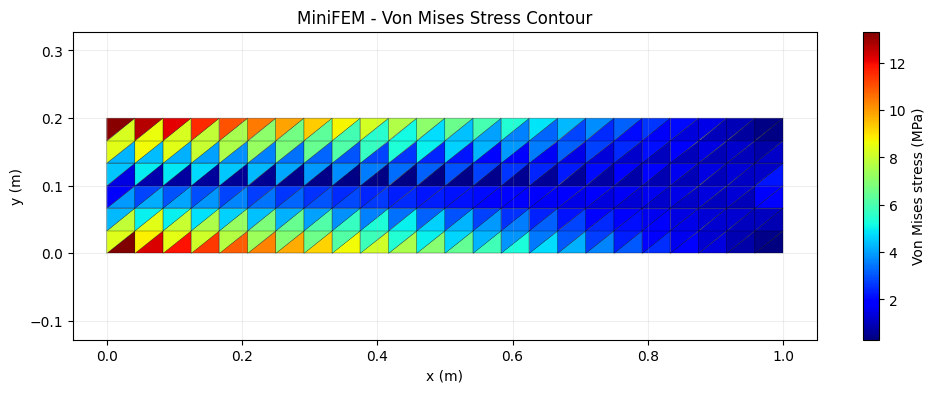

In [4]:
# Step 4: Stress recovery and Von Mises stress plot

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

element_stress = []
element_vm = []
element_centers = []

for element in elements:
    x = nodes[element, 0]
    y = nodes[element, 1]

    # Triangle area
    A = 0.5 * np.linalg.det(np.array([
        [1, x[0], y[0]],
        [1, x[1], y[1]],
        [1, x[2], y[2]]
    ]))

    # Shape function derivatives
    b = np.array([
        y[1] - y[2],
        y[2] - y[0],
        y[0] - y[1]
    ])

    c = np.array([
        x[2] - x[1],
        x[0] - x[2],
        x[1] - x[0]
    ])

    # B matrix
    B = np.zeros((3, 6))
    B[0, 0::2] = b
    B[1, 1::2] = c
    B[2, 0::2] = c
    B[2, 1::2] = b
    B = B / (2 * A)

    # Element displacement vector
    dofs = np.column_stack((2 * element, 2 * element + 1)).ravel()
    Ue = U[dofs]

    # Strain and stress
    strain = B @ Ue
    stress = D @ strain

    sigma_x = stress[0]
    sigma_y = stress[1]
    tau_xy  = stress[2]

    # Von Mises stress (plane stress)
    vm = np.sqrt(sigma_x**2 - sigma_x * sigma_y + sigma_y**2 + 3 * tau_xy**2)

    element_stress.append(stress)
    element_vm.append(vm)
    element_centers.append([np.mean(x), np.mean(y)])

element_stress = np.array(element_stress)
element_vm = np.array(element_vm)
element_centers = np.array(element_centers)

print("=== Stress Results ===")
print("Maximum Von Mises stress:", np.max(element_vm) / 1e6, "MPa")
print("Minimum Von Mises stress:", np.min(element_vm) / 1e6, "MPa")

# Plot Von Mises stress contour (element-centered)
plt.figure(figsize=(12, 4))

tpc = plt.tripcolor(
    nodes[:, 0],
    nodes[:, 1],
    elements,
    facecolors=element_vm / 1e6,   # MPa
    edgecolors='k',
    linewidth=0.2,
    cmap='jet'
)

plt.colorbar(tpc, label="Von Mises stress (MPa)")
plt.title("MiniFEM - Von Mises Stress Contour")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.axis("equal")
plt.grid(alpha=0.2)
plt.show()

In [5]:

# Step 5: Numerical verification
# Compare FEM with beam theory

import numpy as np

# 1. Euler-Bernoulli beam theory
I = thickness * H**3 / 12

delta_EB = P * L**3 / (3 * E * I)

# 2. Timoshenko beam theory
# Includes approximate shear deformation

G = E / (2 * (1 + nu))
kappa = 5 / 6
area_section = thickness * H

delta_shear = P * L / (kappa * G * area_section)

delta_T = delta_EB + delta_shear

# 3. FEM result
delta_FEM = abs(uy[load_node])

error_EB = abs(delta_FEM - delta_EB) / delta_EB * 100
error_T = abs(delta_FEM - delta_T) / delta_T * 100

print("=== MiniFEM Verification ===")
print(f"Euler-Bernoulli displacement: {delta_EB*1000:.6f} mm")
print(f"Timoshenko displacement:     {delta_T*1000:.6f} mm")
print(f"FEM displacement:            {delta_FEM*1000:.6f} mm")
print(f"Difference vs EB:            {error_EB:.2f}%")
print(f"Difference vs Timoshenko:    {error_T:.2f}%")

# 4. Force equilibrium verification

R = K @ U - F

vertical_reaction = np.sum(R[fixed_dofs[1::2]])
relative_residual = (
    np.linalg.norm(R[free_dofs]) /
    np.linalg.norm(F[free_dofs])
)

print("\n=== Equilibrium Check ===")
print(f"Applied downward force: {-P:.2f} N")
print(f"Vertical support reaction: {vertical_reaction:.2f} N")
print(f"Relative solver residual: {relative_residual:.3e}")

assert np.isclose(vertical_reaction, P, rtol=1e-8)
assert relative_residual < 1e-7

print("Equilibrium verification PASSED!")


=== MiniFEM Verification ===
Euler-Bernoulli displacement: 0.238095 mm
Timoshenko displacement:     0.245524 mm
FEM displacement:            0.219477 mm
Difference vs EB:            7.82%
Difference vs Timoshenko:    10.61%

=== Equilibrium Check ===
Applied downward force: -1000.00 N
Vertical support reaction: 1000.00 N
Relative solver residual: 1.521e-12
Equilibrium verification PASSED!


Elements:   128 | Displacement: 0.194643 mm
Elements:   288 | Displacement: 0.219226 mm
Elements:  1152 | Displacement: 0.237519 mm
Elements:  4608 | Displacement: 0.242693 mm
Elements: 10368 | Displacement: 0.243699 mm


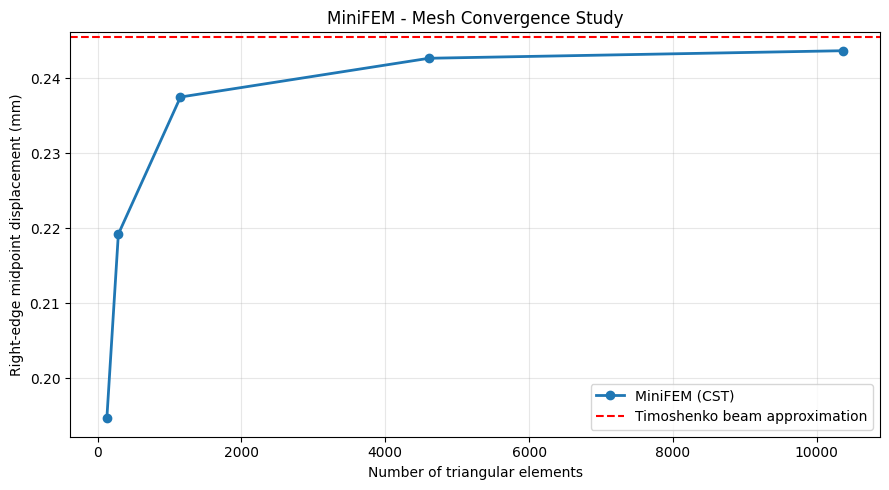

In [6]:

# Step 6: Mesh convergence study
# MiniFEM - 2D Linear Elasticity

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

def solve_mesh(nx, ny):

    # Generate nodes
    xx, yy = np.meshgrid(
        np.linspace(0, L, nx + 1),
        np.linspace(0, H, ny + 1)
    )
    pts = np.column_stack((xx.ravel(), yy.ravel()))

    # Generate CST elements
    elems = []
    for j in range(ny):
        for i in range(nx):
            n0 = j * (nx + 1) + i
            n1 = n0 + 1
            n2 = n0 + nx + 1
            n3 = n2 + 1
            elems.extend([
                [n0, n1, n3],
                [n0, n3, n2]
            ])

    # Assemble stiffness matrix
    rows, cols, values = [], [], []

    for el in elems:
        x = pts[el, 0]
        y = pts[el, 1]

        A = 0.5 * np.linalg.det(
            np.column_stack((np.ones(3), x, y))
        )

        b = np.array([
            y[1]-y[2], y[2]-y[0], y[0]-y[1]
        ])
        c = np.array([
            x[2]-x[1], x[0]-x[2], x[1]-x[0]
        ])

        B = np.zeros((3, 6))
        B[0, 0::2] = b
        B[1, 1::2] = c
        B[2, 0::2] = c
        B[2, 1::2] = b
        B /= 2 * A

        Ke = thickness * A * (B.T @ D @ B)

        dofs = np.column_stack(
            (2*np.array(el), 2*np.array(el)+1)
        ).ravel()

        rows.extend(np.repeat(dofs, 6))
        cols.extend(np.tile(dofs, 6))
        values.extend(Ke.ravel())

    ndof = 2 * len(pts)

    Kmesh = coo_matrix(
        (values, (rows, cols)),
        shape=(ndof, ndof)
    ).tocsr()

    # Uniform vertical traction on right boundary
    Fmesh = np.zeros(ndof)

    right = np.where(
        np.isclose(pts[:, 0], L)
    )[0]

    right = right[np.argsort(pts[right, 1])]

    for a, bnode in zip(right[:-1], right[1:]):
        dy = pts[bnode, 1] - pts[a, 1]
        nodal_force = -P * dy / (2 * H)

        Fmesh[2*a+1] += nodal_force
        Fmesh[2*bnode+1] += nodal_force

    # Fixed boundary
    fixed = np.where(
        np.isclose(pts[:, 0], 0)
    )[0]

    fixed_dofs = np.column_stack(
        (2*fixed, 2*fixed+1)
    ).ravel()

    free = np.setdiff1d(
        np.arange(ndof), fixed_dofs
    )

    # Solve
    Um = np.zeros(ndof)
    Um[free] = spsolve(
        Kmesh[free][:, free],
        Fmesh[free]
    )

    # Right-edge midpoint displacement
    tip = right[len(right)//2]
    return abs(Um[2*tip+1]) * 1000


# Run multiple mesh resolutions
mesh_sizes = [
    (16, 4),
    (24, 6),
    (48, 12),
    (96, 24),
    (144, 36)
]

results = []
element_counts = []

for nx_i, ny_i in mesh_sizes:
    displacement = solve_mesh(nx_i, ny_i)
    count = 2 * nx_i * ny_i

    results.append(displacement)
    element_counts.append(count)

    print(
        f"Elements: {count:5d} | "
        f"Displacement: {displacement:.6f} mm"
    )

# Plot convergence
plt.figure(figsize=(9, 5))

plt.plot(
    element_counts,
    results,
    "o-",
    linewidth=2,
    label="MiniFEM (CST)"
)

plt.axhline(
    y=delta_T * 1000,
    color="red",
    linestyle="--",
    label="Timoshenko beam approximation"
)

plt.xlabel("Number of triangular elements")
plt.ylabel("Right-edge midpoint displacement (mm)")
plt.title("MiniFEM - Mesh Convergence Study")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("mesh_convergence.png", dpi=300)
plt.show()
